# Distância de rede à estação de trem/metrô mais próxima — r5py

Calcula, para cada zona OD do município de São Paulo, a **distância caminhando pela rede viária** do
centroide até a estação de trem/metrô mais próxima. É a contrapartida "de rede" da distância
euclidiana de `08_cria_base_covariaveis_zona.ipynb` (que também grava as estações em
`estacoes_trilho.gpkg`).

Motor: **r5py** (R5 da Conveyal), o mesmo do repositório `process_gtfs`. Rede só com o extrato OSM, sem
GTFS — o trajeto é inteiramente a pé. Em duas etapas:

1. `TravelTimeMatrix` zona × estação (todas contra todas) a pé → a estação mais próxima **por tempo de
   caminhada na rede**, que pode não ser a mais próxima em linha reta (rio, ferrovia, morro, cerca);
2. `DetailedItineraries` só para o par escolhido de cada zona → distância percorrida em metros.

**Ressalvas.** O centroide é "colado" na rua mais próxima antes do roteamento (`snap_to_network`), então
a distância não inclui o trecho do centroide até a rua. Zonas grandes e rurais (Marsilac, Parelheiros)
têm o centroide longe de tudo, e a distância é a de um único ponto — não a média dos moradores.

Saída: `../outputs/01/dist_rede_estacao_zona.parquet`.

## Seção 0 — Java, r5py e configuração

O r5py precisa de um JDK 21. `scripts/install_java.py` usa o de `Dados/java/` (git-ignorado) ou baixa o
Temurin se não houver. **`JAVA_HOME` e `--max-memory` têm de ser definidos antes do primeiro
`import r5py`** — o jpype resolve a JVM no momento do import.

In [1]:
import os
import sys
from datetime import timedelta
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../scripts").resolve()))
from install_java import garantir_java

os.environ["JAVA_HOME"] = str(garantir_java())
MAX_MEMORY = "16G"
if "--max-memory" not in sys.argv:
    sys.argv.extend(["--max-memory", MAX_MEMORY])
import r5py   # so depois de JAVA_HOME e --max-memory

CRS_WGS84 = 4326
CRS_LOCAL_UTM = 31983   # SIRGAS 2000 / UTM zone 23S
COD_MUNI_SP = 36

SHP_ZONAS = Path("../Dados/pacote-anexos-od_10-02-25_0/002_Site Metro Mapas/Shape/Zonas_2023.shp")
PBF = Path("../Dados/r5/sao_paulo/sao_paulo.osm.pbf")
DIR_SAIDA = Path("../outputs/01")

MAX_TEMPO = timedelta(hours=8)   # folgado: o extremo sul fica a >20 km em linha reta de uma estacao
VELOCIDADE_KMH = 3.6             # padrao do R5 (speed_walking)
print(f"r5py {r5py.__version__} | JAVA_HOME = {os.environ['JAVA_HOME']}")

r5py 1.1.7 | JAVA_HOME = C:\Users\9837292\Documents\GitHub\tarifa_zero_sptrans\Dados\java\jdk-21


## Seção 1 — origens (centroides das zonas) e destinos (estações)

In [2]:
zonas = gpd.read_file(SHP_ZONAS).to_crs(CRS_LOCAL_UTM)
zonas = zonas[zonas["NumeroMuni"] == COD_MUNI_SP].reset_index(drop=True)
origens = gpd.GeoDataFrame(
    {"id": zonas["NumeroZona"].astype(int)}, geometry=zonas.geometry.centroid, crs=CRS_LOCAL_UTM
).to_crs(CRS_WGS84)

estacoes = gpd.read_file(DIR_SAIDA / "estacoes_trilho.gpkg").to_crs(CRS_WGS84)
destinos = estacoes[["stop_id", "estacao", "linha", "geometry"]].rename(columns={"stop_id": "id"})
assert destinos["id"].is_unique
print(f"origens (zonas de SP): {len(origens)} | destinos (paradas de trilho): {len(destinos)}")

origens (zonas de SP): 343 | destinos (paradas de trilho): 198


## Seção 2 — rede viária

Só o extrato OSM. A construção da `TransportNetwork` leva alguns minutos e vários GB de memória.

In [3]:
rede = r5py.TransportNetwork(str(PBF))
print("rede construida")

rede construida


## Seção 3 — estação mais próxima por tempo de caminhada

Matriz de tempos zona × estação a pé. `travel_time` vem em minutos; o par sem rota fica `NaN`. A estação
escolhida é a de menor tempo — com velocidade constante, é a de menor distância pela rede.

In [4]:
matriz = r5py.TravelTimeMatrix(
    rede, origins=origens, destinations=destinos,
    transport_modes=[r5py.TransportMode.WALK],
    max_time=MAX_TEMPO, max_time_walking=MAX_TEMPO, speed_walking=VELOCIDADE_KMH,
    snap_to_network=True,
)
print(f"pares: {len(matriz):,} | sem rota: {matriz['travel_time'].isna().mean():.1%}")

mais_proxima = (
    matriz.dropna(subset=["travel_time"]).assign(NumeroZona=lambda d: d["from_id"].astype(int))   # os ids voltam como texto
    .sort_values(["NumeroZona", "travel_time", "to_id"]).drop_duplicates("NumeroZona")
    .rename(columns={"to_id": "stop_id", "travel_time": "tempo_a_pe_min"})
    .merge(estacoes[["stop_id", "estacao"]], on="stop_id")
)
sem_rota = sorted(set(origens["id"]) - set(mais_proxima["NumeroZona"]))
print(f"zonas com estacao alcancavel: {len(mais_proxima)} de {len(origens)} | sem rota: {len(sem_rota)} {sem_rota}")

pares: 67,914 | sem rota: 25.4%
zonas com estacao alcancavel: 343 de 343 | sem rota: 0 []


## Seção 4 — distância percorrida no par escolhido

`DetailedItineraries` com origens e destinos de mesmo tamanho roteia **par a par** (o i-ésimo destino é o
da i-ésima origem). A distância do par é a soma dos trechos da viagem.

In [5]:
pares = mais_proxima[["NumeroZona", "stop_id"]].reset_index(drop=True)
geo_zona = origens.set_index("id").geometry
geo_estacao = estacoes.set_index("stop_id").geometry
orig_sel = gpd.GeoDataFrame({"id": pares["NumeroZona"]}, geometry=geo_zona.loc[pares["NumeroZona"]].values, crs=CRS_WGS84)
# ids dos destinos unicos ("zona_estacao"): varias zonas escolhem a mesma estacao
dest_sel = gpd.GeoDataFrame({"id": pares["NumeroZona"].astype(str) + "_" + pares["stop_id"]},
                            geometry=geo_estacao.loc[pares["stop_id"]].values, crs=CRS_WGS84)

roteiros = r5py.DetailedItineraries(
    rede, origins=orig_sel, destinations=dest_sel,
    transport_modes=[r5py.TransportMode.WALK],
    max_time=MAX_TEMPO, max_time_walking=MAX_TEMPO, speed_walking=VELOCIDADE_KMH,
    snap_to_network=True,
)
roteiros["tempo_min"] = roteiros["travel_time"].dt.total_seconds() / 60   # vem como timedelta
# soma dos trechos de cada opcao de itinerario; a pe so ha uma opcao, mas fica a menor por garantia
por_opcao = roteiros.groupby(["from_id", "option"]).agg(dist_m=("distance", "sum"), tempo_itinerario_min=("tempo_min", "sum"))
dist = por_opcao.groupby("from_id").min().reset_index().assign(NumeroZona=lambda d: d["from_id"].astype(int))
print(f"pares com itinerario: {len(dist)} de {len(pares)}")

pares com itinerario: 343 de 343


## Seção 5 — conferência e gravação

A distância pela rede não pode ser menor que a euclidiana (a menos do deslocamento do `snap`).
A razão rede / reta (fator de circuidade) costuma ficar entre 1,2 e 1,5 em malha urbana.

zonas com distancia de rede MENOR que a euclidiana por mais de 300 m: 0
zonas sem distancia de rede: 0
       dist_estacao_eucl_km  dist_estacao_rede_km  circuidade
count                343.00                343.00      343.00
mean                   1.83                  2.49        1.41
std                    1.90                  2.57        0.42
min                    0.05                  0.05        1.03
25%                    0.73                  1.00        1.22
50%                    1.20                  1.76        1.31
75%                    2.24                  3.11        1.45
max                   19.53                 25.56        5.01

dist / (velocidade x tempo): mediana 1.01 (esperado ~1; tempo vem arredondado em minutos)
zonas em que a estacao mais proxima pela rede difere da mais proxima em linha reta: 50


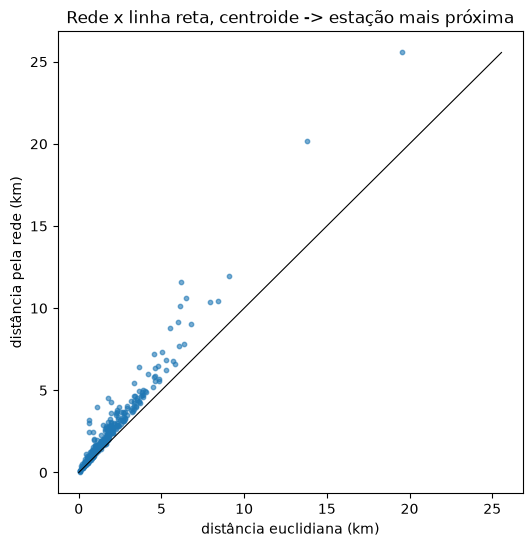

In [6]:
eucl = pd.read_parquet(DIR_SAIDA / "covariaveis_zona.parquet")[["NumeroZona", "dist_estacao_eucl_km", "estacao_mais_proxima"]]
saida = (
    mais_proxima[["NumeroZona", "estacao", "tempo_a_pe_min"]]
    .merge(dist[["NumeroZona", "dist_m"]], on="NumeroZona", how="left")
    .assign(dist_estacao_rede_km=lambda d: d["dist_m"] / 1000)
    .rename(columns={"estacao": "estacao_rede"})
    .drop(columns="dist_m")
    .merge(eucl, on="NumeroZona", how="right")
)

saida["circuidade"] = saida["dist_estacao_rede_km"] / saida["dist_estacao_eucl_km"]
viola = saida[saida["dist_estacao_rede_km"] < saida["dist_estacao_eucl_km"] - 0.3]
print(f"zonas com distancia de rede MENOR que a euclidiana por mais de 300 m: {len(viola)}")
print(f"zonas sem distancia de rede: {saida['dist_estacao_rede_km'].isna().sum()}")
print(saida[["dist_estacao_eucl_km", "dist_estacao_rede_km", "circuidade"]].describe().round(2).to_string())

# consistencia interna: tempo do itinerario x distancia / velocidade
cheque = (saida["dist_estacao_rede_km"] / VELOCIDADE_KMH * 60 / saida["tempo_a_pe_min"]).dropna()
print(f"\ndist / (velocidade x tempo): mediana {cheque.median():.2f} (esperado ~1; tempo vem arredondado em minutos)")
print(f"zonas em que a estacao mais proxima pela rede difere da mais proxima em linha reta: "
      f"{(saida['estacao_rede'] != saida['estacao_mais_proxima']).sum()}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(saida["dist_estacao_eucl_km"], saida["dist_estacao_rede_km"], s=10, alpha=.6)
lim = np.nanmax(saida[["dist_estacao_eucl_km", "dist_estacao_rede_km"]].to_numpy())
ax.plot([0, lim], [0, lim], color="k", lw=.8)
ax.set_xlabel("distância euclidiana (km)"); ax.set_ylabel("distância pela rede (km)")
ax.set_title("Rede x linha reta, centroide -> estação mais próxima")
plt.show()

In [7]:
assert len(viola) == 0, "distancia de rede menor que a euclidiana: revisar snap/rede"
saida = saida[["NumeroZona", "dist_estacao_rede_km", "tempo_a_pe_min", "estacao_rede", "circuidade"]]
saida.to_parquet(DIR_SAIDA / "dist_rede_estacao_zona.parquet", index=False)
print(f"dist_rede_estacao_zona.parquet: {len(saida)} zonas")
saida.head()

dist_rede_estacao_zona.parquet: 343 zonas


,NumeroZona,dist_estacao_rede_km,tempo_a_pe_min,estacao_rede,circuidade
0,1,0.244071,4.0,Sé,1.256682
1,2,0.708547,12.0,São Bento,1.565407
2,3,0.485143,8.0,Sé,1.475767
3,4,0.734718,12.0,Anhangabaú,1.499393
4,5,0.050062,0.0,República,1.088269
